# 03 · Performance Persistence: does residual alpha predict residual alpha?

**Question.** If a fund beat its investable replication over the last three years, should an
allocator expect it to keep doing so? And can machine learning extract more out-of-sample signal
than a simple sort, or does it just overfit?

**Design (no look-ahead).** Every December from 2008 to 2024 a *cohort* is formed:
* **Formation (36 months back):** RBSA replication, residual alpha and its t-stat, raw and
  category-relative return, Sharpe, R², tracking error, volatility, fee, vehicle, age.
* **Evaluation (12 months forward):** the fund's return minus its **frozen** replicating portfolio,
  i.e. out-of-sample residual performance an investor could not have bought through index exposures.

Tests: quintile sorts with Newey–West t-stats across cohorts, quintile transition matrix, decay of
predictability over 1–5 years, and a walk-forward comparison of linear, gradient-boosting and
neural-network models, all benchmarked against an oracle that knows the true skill.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor
from pfquant import make_universe, stats, plotting
plotting.setup()
pd.set_option("display.float_format", "{:.3f}".format)
torch.set_num_threads(2)

USE_REAL_DATA = False
if USE_REAL_DATA:
    from pfquant.real_data import load_real_universe
    uni = load_real_universe()
else:
    uni = make_universe()
R, F, funds = uni.fund_returns, uni.factor_returns, uni.funds
HAS_TRUTH = uni.true_weights is not None
active = funds.index[~funds["passive"].astype(bool)]
print(f"{len(active)} active funds analysed (passive funds have no alpha to persist)")

427 active funds analysed (passive funds have no alpha to persist)


## 1. Build the fund-year panel

In [2]:
Rv, Fv = R.to_numpy(), F.to_numpy()
col = {f: i for i, f in enumerate(R.columns)}
cat = funds["category"]
H = 5                                                   # forward years tracked for the decay study
rows = []
for a in range(36, len(R) - 12 + 1, 12):
    form = slice(a - 36, a)
    cat_ret = {}
    for f in active:
        y = Rv[form, col[f]]
        if np.isnan(y).any():
            continue
        w, al, res, r2 = stats.rbsa(y, Fv[form])
        ex = res + al
        row = dict(date=R.index[a - 1], fund=f, category=cat[f],
                   ret_36=(1 + y).prod() - 1, sharpe_36=y.mean() / y.std() * np.sqrt(12),
                   alpha_36=al * 12, t_alpha_36=stats.newey_west_tstat(ex), r2_36=r2,
                   te_36=res.std() * np.sqrt(12), vol_36=y.std() * np.sqrt(12),
                   alpha_12=ex[-12:].mean() * 12,
                   fee=funds.loc[f, "expense_ratio"], etf=float(funds.loc[f, "vehicle"] == "ETF"),
                   age=(R.index[a - 1] - funds.loc[f, "inception"]).days / 365.25,
                   log_aum=np.log(funds.loc[f, "aum"]))
        for h in range(1, H + 1):
            fw = slice(a + 12 * (h - 1), a + 12 * h)
            if fw.stop <= len(R):
                row[f"fwd_resid_{h}y"] = (Rv[fw, col[f]] - Fv[fw] @ w).mean() * 12
        if HAS_TRUTH:
            fw = slice(a, a + 12)
            row["oracle"] = uni.true_alpha.iloc[fw][f].mean() * 12 - funds.loc[f, "expense_ratio"]
        rows.append(row)
P = pd.DataFrame(rows)
P["cat_rel_36"] = P["ret_36"] - P.groupby(["date", "category"])["ret_36"].transform("mean")
P["target"] = P["fwd_resid_1y"]
print(f"Panel: {len(P):,} fund-years, {P['date'].nunique()} cohorts "
      f"({P['date'].min():%Y}–{P['date'].max():%Y})")
P.head()

Panel: 6,347 fund-years, 17 cohorts (2008–2024)


,date,fund,category,ret_36,sharpe_36,alpha_36,t_alpha_36,r2_36,te_36,vol_36,...,age,log_aum,fwd_resid_1y,fwd_resid_2y,fwd_resid_3y,fwd_resid_4y,fwd_resid_5y,oracle,cat_rel_36,target
0,2008-12-31,F0004,Moderate Allocation,0.050,0.204,0.022,0.693,0.799,0.050,0.111,...,2.916,18.334,0.039,0.015,-0.047,0.021,0.063,-0.019,0.005,0.039
1,2008-12-31,F0005,US Small Cap,0.235,0.470,-0.006,-0.480,0.967,0.034,0.190,...,2.916,19.092,0.014,-0.051,-0.006,0.011,0.029,-0.022,-0.017,0.014
2,2008-12-31,F0008,Moderate Allocation,-0.060,-0.118,-0.043,-2.644,0.943,0.027,0.115,...,2.916,20.544,-0.027,-0.027,-0.054,-0.018,0.030,-0.044,-0.106,-0.027
3,2008-12-31,F0012,US Large Growth,0.274,0.558,0.033,1.648,0.949,0.039,0.173,...,2.916,18.408,0.059,-0.019,0.050,0.019,-0.014,-0.025,0.071,0.059
4,2008-12-31,F0015I,Moderate Allocation,-0.061,-0.069,-0.046,-1.278,0.861,0.053,0.143,...,2.916,18.129,-0.052,0.014,0.043,-0.032,-0.046,-0.022,-0.106,-0.052


## 2. Quintile sorts

Within each cohort, sort funds into quintiles on a formation signal and record the average
out-of-sample residual return of each quintile over the next 12 months. The Q5 − Q1 spread is averaged
across cohorts with a Newey–West t-statistic.

In [3]:
signals = {"ret_36": "Raw 36m return", "cat_rel_36": "Category-relative return", "sharpe_36": "Sharpe ratio",
           "alpha_36": "Residual alpha (36m)", "t_alpha_36": "t-stat of alpha", "alpha_12": "Residual alpha (12m)",
           "fee": "Low fee (sorted ascending)"}

def quintile_returns(df, sig, ascending=True):
    q = df.groupby("date")[sig].transform(lambda s: pd.qcut(s.rank(method="first", ascending=ascending), 5, labels=False))
    return df.assign(q=q + 1).groupby(["date", "q"])["target"].mean().unstack()

sort_tab, spreads = [], {}
for sig, name in signals.items():
    qr = quintile_returns(P, sig, ascending=(sig != "fee"))
    spread = qr[5] - qr[1]
    spreads[name] = spread
    sort_tab.append(dict(signal=name, **{f"Q{i}": qr[i].mean() for i in range(1, 6)},
                         **{"Q5−Q1": spread.mean(), "NW t": stats.newey_west_tstat(spread.values, lags=1),
                            "% cohorts > 0": (spread > 0).mean()}))
sort_tab = pd.DataFrame(sort_tab).set_index("signal")
display(sort_tab.style.format({**{f"Q{i}": "{:.2%}" for i in range(1, 6)}, "Q5−Q1": "{:.2%}",
                              "NW t": "{:.2f}", "% cohorts > 0": "{:.0%}"})
        .background_gradient(subset=["NW t"], cmap="Greens"))

,Q1,Q2,Q3,Q4,Q5,Q5−Q1,NW t,% cohorts > 0
signal,,,,,,,,
Raw 36m return,-1.57%,-0.99%,-1.00%,-0.40%,-0.05%,1.52%,3.97,82%
Category-relative return,-1.99%,-1.04%,-0.79%,-0.33%,0.14%,2.12%,6.18,88%
Sharpe ratio,-1.69%,-1.17%,-0.78%,-0.41%,0.04%,1.73%,4.81,88%
Residual alpha (36m),-1.86%,-1.20%,-0.73%,-0.30%,0.09%,1.95%,6.93,94%
t-stat of alpha,-2.04%,-1.09%,-0.67%,-0.36%,0.14%,2.18%,8.10,94%
Residual alpha (12m),-1.99%,-1.39%,-0.52%,-0.53%,0.42%,2.41%,7.30,94%
Low fee (sorted ascending),-1.29%,-1.01%,-0.84%,-0.64%,-0.23%,1.06%,4.07,88%


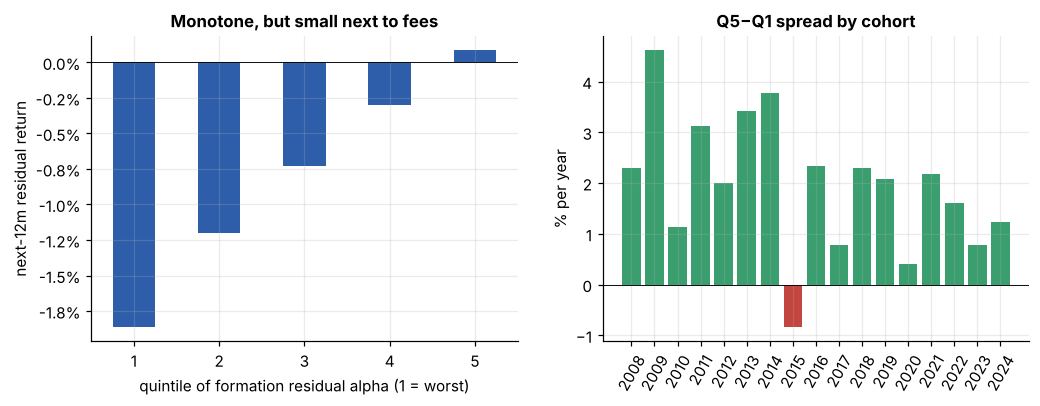

In [4]:
qr = quintile_returns(P, "alpha_36")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
qr.mean().plot.bar(ax=axes[0], color=plotting.PALETTE[0])
axes[0].axhline(0, color="k", lw=0.6)
axes[0].set_xlabel("quintile of formation residual alpha (1 = worst)"); axes[0].set_ylabel("next-12m residual return")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
axes[0].set_title("Monotone, but small next to fees")
axes[0].tick_params(axis="x", rotation=0)
sp = spreads["Residual alpha (36m)"]
axes[1].bar([d.strftime("%Y") for d in sp.index], sp.values * 100,
            color=[plotting.PALETTE[2] if v > 0 else plotting.PALETTE[3] for v in sp.values])
axes[1].axhline(0, color="k", lw=0.6); axes[1].set_ylabel("% per year"); axes[1].tick_params(axis="x", rotation=60)
axes[1].set_title("Q5−Q1 spread by cohort")
plotting.save(fig, "03_quintiles")

## 3. Transition matrix

Probability that a fund in formation-alpha quintile *i* lands in quintile *j* of next-year
residual performance. No persistence would give 20 % everywhere.

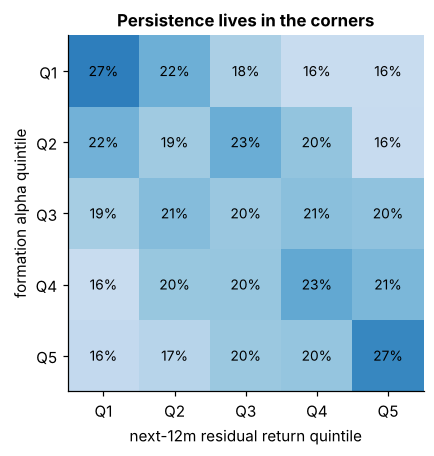

In [5]:
q_form = P.groupby("date")["alpha_36"].transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=False)) + 1
q_next = P.groupby("date")["target"].transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=False)) + 1
T = pd.crosstab(q_form, q_next, normalize="index")
fig, ax = plt.subplots(figsize=(5.2, 4.2))
im = ax.imshow(T.values, cmap="Blues", vmin=0.1, vmax=0.35)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{T.values[i, j]:.0%}", ha="center", va="center", fontsize=9,
                color="white" if T.values[i, j] > 0.28 else "black")
ax.set_xticks(range(5), [f"Q{i}" for i in range(1, 6)]); ax.set_yticks(range(5), [f"Q{i}" for i in range(1, 6)])
ax.set_xlabel("next-12m residual return quintile"); ax.set_ylabel("formation alpha quintile")
ax.set_title("Persistence lives in the corners"); ax.grid(False)
plotting.save(fig, "03_transition")

## 4. How long does it last?

Rank IC (Spearman) between formation alpha and residual return in forward year *h*, with frozen
replication weights. Manager changes and transient alpha should make predictability decay.

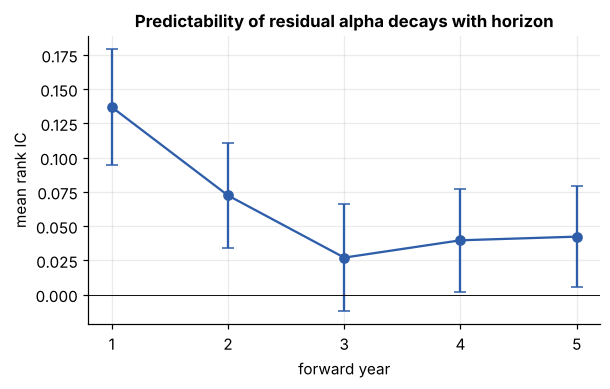

,h,ic,se,n
0,1,0.137,0.022,17
1,2,0.072,0.020,16
2,3,0.027,0.020,15
3,4,0.040,0.019,14
4,5,0.042,0.019,13


In [6]:
decay = []
for h in range(1, H + 1):
    c = f"fwd_resid_{h}y"
    ics = P.dropna(subset=[c]).groupby("date").apply(lambda g: stats.rank_ic(g["alpha_36"].values, g[c].values))
    decay.append(dict(h=h, ic=ics.mean(), se=ics.std() / np.sqrt(len(ics)), n=len(ics)))
decay = pd.DataFrame(decay)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.errorbar(decay["h"], decay["ic"], yerr=1.96 * decay["se"], marker="o", capsize=4)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("forward year"); ax.set_ylabel("mean rank IC"); ax.set_xticks(range(1, H + 1))
ax.set_title("Predictability of residual alpha decays with horizon")
plotting.save(fig, "03_decay")
decay

## 5. Walk-forward machine learning

Can a model combine the signals better than a single sort? Each cohort is predicted by models trained
**only on earlier cohorts** (expanding window, at least 5 cohorts of history). Targets are
cross-sectionally demeaned so the models learn *relative* performance.

* **Single signal:** formation residual alpha.
* **Ridge regression** on all features.
* **Gradient boosting** (sklearn `HistGradientBoostingRegressor`).
* **Neural network:** PyTorch MLP, ensemble of 5 seeds, early stopping on the most recent training cohort.
* **Oracle:** true net alpha over the forward year (simulation only), the ceiling for any model.

In [7]:
features = ["alpha_36", "t_alpha_36", "alpha_12", "ret_36", "cat_rel_36", "sharpe_36", "r2_36",
            "te_36", "vol_36", "fee", "etf", "age", "log_aum"]
P["y_rel"] = P["target"] - P.groupby("date")["target"].transform("mean")

def to_cs_ranks(df):            # cross-sectional rank-gauss transform per cohort: robust, scale-free
    from scipy.stats import norm
    r = df.groupby("date")[features].rank(pct=True)
    return pd.DataFrame(norm.ppf(r.clip(0.005, 0.995)), index=df.index, columns=features).astype(np.float32)
Xall = to_cs_ranks(P)

class MLP(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, 32), nn.SiLU(), nn.Dropout(0.2), nn.Linear(32, 16), nn.SiLU(),
                                 nn.Linear(16, 1))
    def forward(self, x): return self.net(x).squeeze(-1)

def fit_mlp(X, y, Xv, yv, seed):
    torch.manual_seed(seed)
    m = MLP(X.shape[1]); opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=1e-3)
    X, y = torch.tensor(X), torch.tensor(y, dtype=torch.float32) * 100
    Xv, yv = torch.tensor(Xv), torch.tensor(yv, dtype=torch.float32) * 100
    best, best_state, patience = np.inf, None, 0
    for ep in range(200):
        m.train(); perm = torch.randperm(len(X))
        for b in range(0, len(X), 256):
            i = perm[b:b + 256]; opt.zero_grad()
            nn.functional.mse_loss(m(X[i]), y[i]).backward(); opt.step()
        m.eval()
        with torch.no_grad(): v = nn.functional.mse_loss(m(Xv), yv).item()
        if v < best - 1e-4: best, best_state, patience = v, {k: t.clone() for k, t in m.state_dict().items()}, 0
        else:
            patience += 1
            if patience >= 15: break
    m.load_state_dict(best_state); return m

dates = sorted(P["date"].unique())
preds = []
for k, d in enumerate(dates):
    if k < 5:
        continue
    tr = P["date"] < d; te_ = P["date"] == d
    Xtr, ytr, Xte = Xall[tr].values, P.loc[tr, "y_rel"].values, Xall[te_].values
    out = P.loc[te_, ["date", "fund", "target"] + (["oracle"] if HAS_TRUTH else [])].copy()
    out["Single signal (alpha)"] = P.loc[te_, "alpha_36"].values
    out["Ridge"] = RidgeCV(alphas=np.logspace(-2, 3, 20)).fit(Xtr, ytr).predict(Xte)
    out["Gradient boosting"] = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.03, max_depth=3,
                                                             min_samples_leaf=50, random_state=0).fit(Xtr, ytr).predict(Xte)
    last = P.loc[tr, "date"] == dates[k - 1]
    ens = []
    for seed in range(5):
        m = fit_mlp(Xtr[~last.values], ytr[~last.values], Xtr[last.values], ytr[last.values], seed)
        with torch.no_grad(): ens.append(m(torch.tensor(Xte)).numpy())
    out["Neural net (MLP ×5)"] = np.mean(ens, 0)
    preds.append(out)
Pr = pd.concat(preds)
models = ["Single signal (alpha)", "Ridge", "Gradient boosting", "Neural net (MLP ×5)"] + (["oracle"] if HAS_TRUTH else [])
print(f"Walk-forward test cohorts: {Pr['date'].nunique()} ({Pr['date'].min():%Y}–{Pr['date'].max():%Y})")

Walk-forward test cohorts: 12 (2013–2024)


In [8]:
res = []
for m in models:
    ic = Pr.groupby("date").apply(lambda g: stats.rank_ic(g[m].values, g["target"].values))
    q = Pr.groupby("date")[m].transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=False))
    spread = Pr[q == 4].groupby("date")["target"].mean() - Pr[q == 0].groupby("date")["target"].mean()
    res.append({"model": "Oracle (true skill, unknowable)" if m == "oracle" else m, "mean rank IC": ic.mean(),
                "IC NW t": stats.newey_west_tstat(ic.values, lags=1), "IC > 0 (% cohorts)": (ic > 0).mean(),
                "Top−bottom quintile, p.a.": spread.mean(), "spread NW t": stats.newey_west_tstat(spread.values, lags=1)})
res = pd.DataFrame(res).set_index("model")
display(res.style.format({"mean rank IC": "{:.3f}", "IC NW t": "{:.2f}", "IC > 0 (% cohorts)": "{:.0%}",
                          "Top−bottom quintile, p.a.": "{:.2%}", "spread NW t": "{:.2f}"}))

,mean rank IC,IC NW t,IC > 0 (% cohorts),"Top−bottom quintile, p.a.",spread NW t
model,,,,,
Single signal (alpha),0.112,5.34,92%,1.67%,5.44
Ridge,0.132,5.74,92%,2.05%,5.11
Gradient boosting,0.102,3.70,83%,1.66%,3.25
Neural net (MLP ×5),0.128,5.40,92%,2.05%,5.28
"Oracle (true skill, unknowable)",0.528,15.93,100%,8.10%,21.14


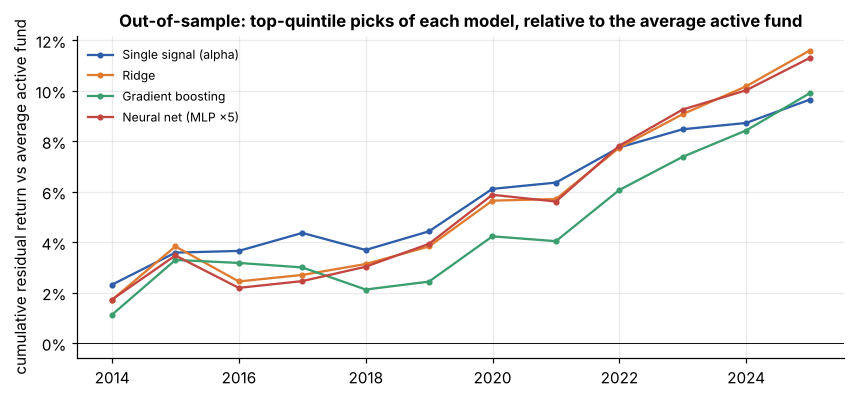

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for m in models[:-1] if HAS_TRUTH else models:
    q = Pr.groupby("date")[m].transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=False))
    top = Pr[q == 4].groupby("date")["target"].mean() - Pr.groupby("date")["target"].mean()
    ax.plot(top.index, top.cumsum(), marker="o", ms=3, label=m)
ax.axhline(0, color="k", lw=0.6)
ax.set_ylabel("cumulative residual return vs average active fund")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Out-of-sample: top-quintile picks of each model, relative to the average active fund")
ax.legend(fontsize=8)
plotting.save(fig, "03_walk_forward")

### What drives the predictions?
Permutation importance of the gradient-boosting model on the pooled out-of-sample cohorts
(refit once on all but the last 5 cohorts, scored on those 5).

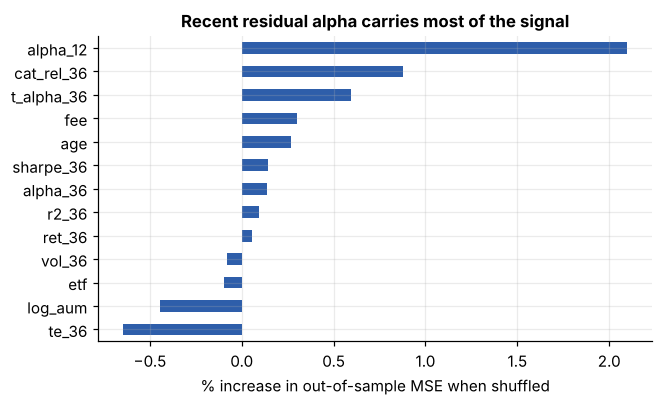

In [10]:
cut = dates[-5]
tr, te_ = P["date"] < cut, P["date"] >= cut
g = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.03, max_depth=3, min_samples_leaf=50,
                                  random_state=0).fit(Xall[tr], P.loc[tr, "y_rel"])
Xte, yte = Xall[te_].values, P.loc[te_, "y_rel"].values
base = np.mean((g.predict(Xte) - yte) ** 2)
rng = np.random.default_rng(0)
imp = {}
for j, f in enumerate(features):
    d = []
    for _ in range(5):
        Xp = Xte.copy(); Xp[:, j] = rng.permutation(Xp[:, j]); d.append(np.mean((g.predict(Xp) - yte) ** 2) - base)
    imp[f] = np.mean(d)
imp = pd.Series(imp).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
(imp / base * 100).plot.barh(ax=ax, color=plotting.PALETTE[0])
ax.set_xlabel("% increase in out-of-sample MSE when shuffled")
ax.set_title("Recent residual alpha carries most of the signal")
plotting.save(fig, "03_importance")

## Takeaways

* **Persistence exists, and it is *residual* persistence.** Sorting active funds on residual alpha gives
  a monotone quintile pattern: top-minus-bottom ≈ 2 % a year, positive in 16 of 17 cohorts. Measures
  that control for noise (the t-stat of alpha) or for exposures (category-relative return) beat raw
  return and Sharpe, which mix in factor bets. A low-fee sort works too, but is the weakest of the set.
* **It decays.** Rank IC drops from ≈0.14 in the first forward year to ≈0.03–0.04 by years 3–5, as
  managers change and transient alpha mean-reverts. Rankings need annual refreshes.
* **ML adds a little, not a lot.** Walk-forward ridge and the neural-net ensemble raise the IC from
  ≈0.11 (single signal) to ≈0.13 and the top-minus-bottom spread from ≈1.7 % to ≈2.0 % a year;
  gradient boosting overfits and does worse. All are far below the oracle (IC ≈0.53), a reminder that
  with ~400 funds a year and low signal-to-noise, robust features and honest out-of-sample tests
  matter more than model complexity.

**Limitations.** Real data would add survivorship bias (dead funds must be kept in each cohort),
overlapping share classes (cluster them before testing), and look-ahead in fee and AUM data.